In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [8]:
df=pd.read_csv("D:\\Github\\Rain-Predictor\\data\\raw\\karachi_hourly.csv")
df['time']=pd.to_datetime(df['time'])
df=df.sort_values("time").reset_index(drop=True)
df.head(), df.shape


(                 time  temperature_2m  relative_humidity_2m  pressure_msl  \
 0 2020-01-01 00:00:00            14.2                    68        1017.3   
 1 2020-01-01 01:00:00            13.8                    67        1017.1   
 2 2020-01-01 02:00:00            13.4                    65        1016.7   
 3 2020-01-01 03:00:00            13.3                    63        1016.6   
 4 2020-01-01 04:00:00            13.0                    64        1016.6   
 
    cloud_cover  wind_speed_10m  wind_direction_10m  precipitation  rain  \
 0           26            22.1                  62            0.0   0.0   
 1           25            23.8                  58            0.0   0.0   
 2           62            25.0                  57            0.0   0.0   
 3           52            26.1                  55            0.0   0.0   
 4           70            27.6                  54            0.0   0.0   
 
     latitude  longitude      timezone  
 0  24.850615  66.992485  Asia/

In [13]:
df.info()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52608 entries, 0 to 52607
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   time                  52608 non-null  datetime64[ns]
 1   temperature_2m        52608 non-null  float64       
 2   relative_humidity_2m  52608 non-null  int64         
 3   pressure_msl          52608 non-null  float64       
 4   cloud_cover           52608 non-null  int64         
 5   wind_speed_10m        52608 non-null  float64       
 6   wind_direction_10m    52608 non-null  int64         
 7   precipitation         52608 non-null  float64       
 8   rain                  52608 non-null  float64       
 9   latitude              52608 non-null  float64       
 10  longitude             52608 non-null  float64       
 11  timezone              52608 non-null  object        
dtypes: datetime64[ns](1), float64(7), int64(3), object(1)
memory usage: 4.8+ M

,count,mean,min,25%,50%,75%,max,std
time,52608,2022-12-31 23:30:00,2020-01-01 00:00:00,2021-07-01 23:45:00,2022-12-31 23:30:00,2024-07-01 23:15:00,2025-12-31 23:00:00,NaN
temperature_2m,52608.0,26.238768,8.9,23.3,27.3,29.6,42.9,4.896681
relative_humidity_2m,52608.0,67.44115,4.0,55.0,73.0,84.0,100.0,21.271833
pressure_msl,52608.0,1008.56377,990.6,1003.0,1008.7,1014.3,1024.6,6.737089
cloud_cover,52608.0,31.18788,0.0,0.0,9.0,62.0,100.0,38.196199
wind_speed_10m,52608.0,16.202353,0.0,10.5,15.2,21.3,47.1,7.492999
wind_direction_10m,52608.0,220.049973,1.0,217.0,250.0,271.0,360.0,91.764144
precipitation,52608.0,0.035979,0.0,0.0,0.0,0.0,43.2,0.472385
rain,52608.0,0.035979,0.0,0.0,0.0,0.0,43.2,0.472385
latitude,52608.0,24.850615,24.850615,24.850615,24.850615,24.850615,24.850615,0.0


In [31]:
missing=df.isna().sum().sort_values(ascending=False)
missing[missing>0]
missing

time                    0
temperature_2m          0
relative_humidity_2m    0
pressure_msl            0
cloud_cover             0
wind_speed_10m          0
wind_direction_10m      0
precipitation           0
rain                    0
latitude                0
longitude               0
timezone                0
dtype: int64

In [37]:
df['time'].min(),df['time'].max()

# dt=df['time'].diff().value_counts().head()
# dt

(Timestamp('2020-01-01 00:00:00'), Timestamp('2025-12-31 23:00:00'))

In [28]:
df['rain'].describe()

(df['rain']>0).mean()
df.loc[df['rain']>0, 'rain'].quantile([0.5,0.9,0.99])

0.50    0.100
0.90    1.100
0.99    8.278
Name: rain, dtype: float64

C:\Users\Professor\AppData\Local\Temp\ipykernel_7888\4028815761.py:3: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_rain_mm=ts['rain'].resample('M').sum()


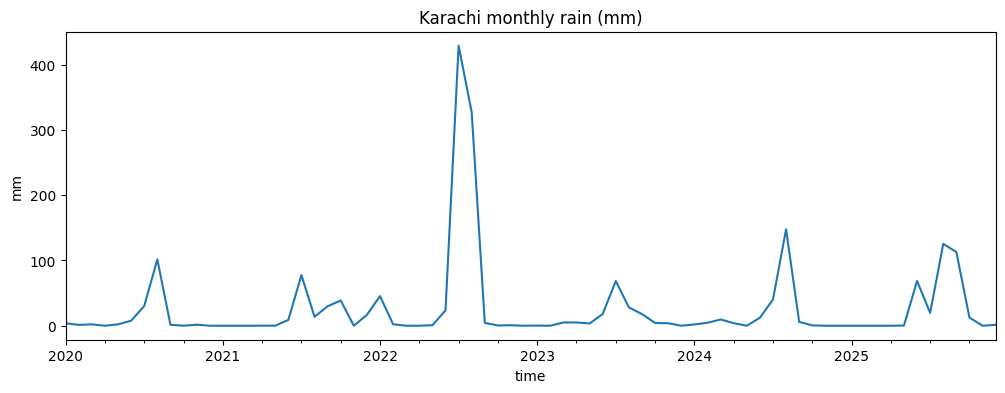

In [ ]:
ts=df.set_index('time')

monthly_rain_mm=ts['rain'].resample('M').sum()
monthly_rain_mm.plot(figsize=(12,4), title="Karachi monthly rain (mm)")
plt.ylabel('mm')
plt.show()




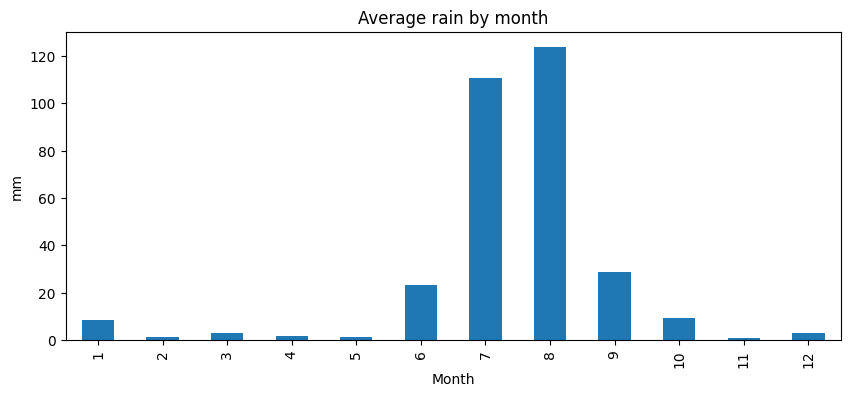

In [34]:
monthly_rain_mm.groupby(monthly_rain_mm.index.month).mean().plot(kind='bar', figsize=(10,4), title='Average rain by month')
plt.xlabel("Month")
plt.ylabel("mm")
plt.show()

In [ ]:
for thr in [0.1, 0.5, 1.0, 2.0, 5.0]:
    rainy_hours = (df["rain"] >= thr).mean()
    print(thr, rainy_hours)


0.1 0.06316529805352798
0.5 0.010853862530413625
1.0 0.006862074209245742
2.0 0.004048813868613139
5.0 0.0014256386861313869
